# Exact Gutzwiller projection-strength scan — standalone NumPy notebook

This notebook evaluates both cell-product Gutzwiller projections on **4 × 4 unit cells** using exact $2^{16}$ subset enumeration:

$$P_{\mathrm{parton}}(g)=\prod_r[1-gQ_r],\qquad Q_r=1-n_r(2-n_r),$$
$$P_{2\mathrm{occ}}(g)=\prod_r[1-gn_{r,c}n_{r,d}].$$

It requires **only NumPy, Matplotlib, and the Python standard library**. There are no imports from the original project, no SciPy, no pandas, no compiled libraries, and no compilation step. The Majorana-Chern-number check admits only even-$\nu_M$ parameter points.

Upload this single `.ipynb` file to the server, edit the parameter cell, and choose **Kernel → Restart & Run All**. Every completed twist link is checkpointed. The exact enumeration is exponential in the number of unit cells; the code is intentionally fixed by default to 16 cells.

## 1. Parameters

`g = 0` is unprojected and `g = 1` is fully projected. Increase `steps_per_leg` to 16 for the finest twist loop used in the original calculation. Reduce `batch_size` if server memory is limited; this changes speed and memory use, not the mathematical result.

In [1]:
import csv
import hashlib
import json
import math
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# Model parameters: the default is the even-nu_M = +2 region.
t = 1.0
t1 = 1.0
m = -2.0
delta_p = 1.0
delta_s = 0.5

# Projection-strength and twist-loop grids.
g_values = np.linspace(0.0, 1.0, 11)
steps_per_leg = 4
pairing_twist = 'cosine'  # 'cosine' or 'linear'

# Numerical controls.
chern_grid = 40
batch_size = 128
reference_mask = None    # Optional fixed reference, e.g. 0xAAC8DA33.
output_directory = Path('projection_strength_results')
resume_from_checkpoint = True

## 2. BdG model and Gaussian ground states

In [2]:
@dataclass(frozen=True)
class ModelParameters:
    t: float = 1.0
    t1: float = 1.0
    m: float = -2.0
    delta_p: float = 1.0
    delta_s: float = 0.5


@dataclass(frozen=True)
class GaussianBCSState:
    z: np.ndarray
    gap: float
    parity: int
    reference_mask: int
    reference_condition: float


class TwoOrbitalModel:
    def __init__(self, lx, ly, params):
        self.lx, self.ly, self.params = int(lx), int(ly), params
        self.n_cells = self.lx * self.ly
        self.n_modes = 2 * self.n_cells

    def cell(self, x, y):
        return (y % self.ly) * self.lx + (x % self.lx)

    def mode(self, x, y, orbital):
        return 2 * self.cell(x, y) + orbital

    def bdg_hamiltonian(self, phi_x=0.0, phi_y=0.0, pairing_twist="cosine"):
        if pairing_twist not in ("cosine", "linear"):
            raise ValueError("pairing_twist must be 'cosine' or 'linear'")
        p, n = self.params, self.n_modes
        h = np.zeros((n, n), dtype=np.complex128)
        delta = np.zeros((n, n), dtype=np.complex128)

        def normal(i, j, amplitude):
            h[i, j] += amplitude
            h[j, i] += np.conjugate(amplitude)

        def pair(i, j, amplitude):
            delta[i, j] += amplitude
            delta[j, i] -= amplitude

        for y in range(self.ly):
            for x in range(self.lx):
                c, d = self.mode(x, y, 0), self.mode(x, y, 1)
                h[c, c] -= p.m
                h[d, d] += p.m
                for direction in ("x", "y"):
                    xp, yp = (x + 1, y) if direction == "x" else (x, y + 1)
                    cx, dx = self.mode(xp, yp, 0), self.mode(xp, yp, 1)
                    phi = phi_x if direction == "x" else phi_y
                    twisted = (x == 0) if direction == "x" else (y == 0)
                    phase = np.exp(1j * phi) if twisted else 1.0
                    if not twisted:
                        pair_phase = 1.0
                    elif pairing_twist == "cosine":
                        pair_phase = np.cos(phi)
                    else:
                        reduced_phi = phi % (2.0 * np.pi)
                        pair_phase = (1.0 - 2.0 * reduced_phi / np.pi if reduced_phi <= np.pi
                                      else 2.0 * reduced_phi / np.pi - 3.0)
                    normal(c, cx, -p.t * phase)
                    normal(d, dx, p.t * phase)
                    interorbital = -1j * p.t1 if direction == "x" else -p.t1
                    normal(c, dx, interorbital * phase)
                    reverse_sign = 1.0 if direction == "x" else -1.0
                    normal(d, cx, reverse_sign * interorbital * phase)
                    if direction == "x":
                        pair(c, cx, -1j * p.delta_p * pair_phase / 4)
                        pair(cx, c, 1j * p.delta_p * pair_phase / 4)
                        pair(d, dx, 1j * p.delta_p * pair_phase / 4)
                        pair(dx, d, -1j * p.delta_p * pair_phase / 4)
                    else:
                        pair(c, cx, -p.delta_p * pair_phase / 4)
                        pair(cx, c, p.delta_p * pair_phase / 4)
                        pair(d, dx, p.delta_p * pair_phase / 4)
                        pair(dx, d, -p.delta_p * pair_phase / 4)
                pair(c, d, -p.delta_s / 2)
                pair(d, c, p.delta_s / 2)
        h_bdg = np.block([[h, delta], [-delta.conj(), -h.T]])
        return 0.5 * (h_bdg + h_bdg.conj().T)


def gaussian_bcs_state(h_bdg, gap_tolerance=1e-8, reference_mask=None):
    n = h_bdg.shape[0] // 2
    energies, vectors = np.linalg.eigh(h_bdg)
    positive = energies[energies > gap_tolerance]
    negative = energies[energies < -gap_tolerance]
    if len(positive) != n or len(negative) != n:
        raise ValueError("The BdG spectrum is gapless or numerically ill-conditioned")
    gap = float(min(np.min(positive), -np.max(negative)))
    positive_vectors = vectors[:, energies > gap_tolerance]
    u, v = positive_vectors[:n].copy(), positive_vectors[n:].copy()
    w = np.block([[u, v.conj()], [v, u.conj()]])
    parity = int(np.linalg.det(w).real < 0.0)
    if parity != 0:
        raise ValueError("Only even-parity Gaussian ground states are supported")
    c = v @ v.conj().T
    base_mask = sum(1 << i for i in range(n) if c[i, i].real > 0.5)
    initial_masks = {0, (1 << n) - 1, base_mask,
                     sum(1 << i for i in range(0, n, 2)),
                     sum(1 << i for i in range(1, n, 2))}
    for threshold in (0.25, 0.75):
        initial_masks.add(sum(1 << i for i in range(n) if c[i, i].real > threshold))
    cache = {}

    def evaluate(mask):
        if mask in cache:
            return cache[mask]
        ud, vd = u.copy(), v.copy()
        for i in range(n):
            if mask & (1 << i):
                ud[i, :], vd[i, :] = v[i, :], u[i, :]
        try:
            condition = float(np.linalg.cond(ud))
        except np.linalg.LinAlgError:
            condition = float("inf")
        cache[mask] = condition, ud, vd
        return cache[mask]

    if reference_mask is not None:
        if not 0 <= reference_mask < (1 << n):
            raise ValueError("reference_mask is inconsistent with the mode count")
        best_mask = reference_mask
        best_condition = evaluate(best_mask)[0]
    else:
        best_mask, best_condition = base_mask, evaluate(base_mask)[0]
        for initial in initial_masks:
            mask, condition = initial, evaluate(initial)[0]
            if condition < best_condition:
                best_mask, best_condition = mask, condition
            for _ in range(6):
                candidate_mask, candidate_condition = mask, condition
                for i in range(n):
                    trial_mask = mask ^ (1 << i)
                    trial_condition = evaluate(trial_mask)[0]
                    if trial_condition < candidate_condition:
                        candidate_mask, candidate_condition = trial_mask, trial_condition
                if candidate_mask == mask:
                    break
                mask, condition = candidate_mask, candidate_condition
                if condition < best_condition:
                    best_mask, best_condition = mask, condition
    if best_condition > 1e10:
        raise ValueError(f"No regular Slater reference found; condition={best_condition:.3e}")
    _, ud, vd = evaluate(best_mask)
    z = -np.linalg.solve(ud.conj().T, vd.conj().T)
    z = 0.5 * (z - z.T)
    return GaussianBCSState(z, gap, parity, best_mask, best_condition)


def twist_loop(steps_per_leg):
    vertices = np.array([[0., 0.], [np.pi, 0.], [np.pi, np.pi],
                         [2*np.pi, np.pi], [2*np.pi, 2*np.pi]])
    points = []
    for leg in range(4):
        for step in range(steps_per_leg):
            f = step / steps_per_leg
            points.append((1-f)*vertices[leg] + f*vertices[leg+1])
    return vertices, np.array(points)


def select_common_states(hamiltonians, n_modes, requested_reference=None):
    if requested_reference is not None:
        return requested_reference, [gaussian_bcs_state(h, reference_mask=requested_reference)
                                    for h in hamiltonians]
    automatic = [gaussian_bcs_state(h) for h in hamiltonians]
    candidates = {state.reference_mask for state in automatic}
    if n_modes == 32:
        candidates.update((0x5057F515, 0xAAC8DA33))
    best = None
    for candidate in sorted(candidates):
        try:
            states = [gaussian_bcs_state(h, reference_mask=candidate) for h in hamiltonians]
        except ValueError:
            continue
        score = max(state.reference_condition for state in states)
        if best is None or score < best[0]:
            best = score, candidate, states
    if best is None:
        raise ValueError("No common regular Slater reference found")
    return best[1], best[2]

In [3]:
def bloch_normal(kx, ky, params):
    p = params
    h = np.zeros((2, 2), dtype=np.complex128)
    h[0, 0] = -p.m - 2*p.t*(np.cos(kx) + np.cos(ky))
    h[1, 1] = p.m + 2*p.t*(np.cos(kx) + np.cos(ky))
    h[0, 1] = -2*p.t1*np.sin(kx) + 2j*p.t1*np.sin(ky)
    h[1, 0] = h[0, 1].conjugate()
    return h


def occupied_bdg_chern(params, grid=40):
    """Fukui occupied-BdG Chern number; only NumPy is required."""
    def bloch_bdg(kx, ky):
        p = params
        h = bloch_normal(kx, ky, p)
        f = -p.delta_p*(np.sin(kx) - 1j*np.sin(ky))
        delta = np.array([[f, -p.delta_s], [p.delta_s, -f]], dtype=np.complex128)
        hm = bloch_normal(-kx, -ky, p)
        return np.block([[h, delta], [delta.conj().T, -hm.T]])

    points = [2*np.pi*i/grid for i in range(grid)]
    occupied = {}
    minimum_gap = float('inf')
    for ix, kx in enumerate(points):
        for iy, ky in enumerate(points):
            energies, vectors = np.linalg.eigh(bloch_bdg(kx, ky))
            minimum_gap = min(minimum_gap, float(energies[2] - energies[1]))
            occupied[ix, iy] = vectors[:, :2]

    def link(a, b):
        value = np.linalg.det(a.conj().T @ b)
        if abs(value) < 1e-14:
            raise ValueError('Singular occupied-band link')
        return value/abs(value)

    curvature = 0.0
    for ix in range(grid):
        for iy in range(grid):
            q = occupied[ix, iy]
            qx = occupied[(ix+1) % grid, iy]
            qy = occupied[ix, (iy+1) % grid]
            qxy = occupied[(ix+1) % grid, (iy+1) % grid]
            plaquette = (link(q, qx)*link(qx, qxy)*
                         np.conjugate(link(qy, qxy))*np.conjugate(link(q, qy)))
            curvature += np.angle(plaquette)
    return float(-curvature/(2*np.pi)), minimum_gap

## 3. Gaussian overlaps and transition Wick matrices

In [4]:
def normalized_gaussian_overlap(z1, z2):
    identity = np.eye(z1.shape[0], dtype=np.complex128)
    det1 = np.linalg.det(identity + z1.conj().T @ z1)
    det2 = np.linalg.det(identity + z2.conj().T @ z2)
    det12 = np.linalg.det(identity + z1.conj().T @ z2)
    norm1, norm2 = float(np.sqrt(det1.real)), float(np.sqrt(det2.real))
    if norm1 <= 0 or norm2 <= 0:
        raise ValueError("Zero-norm BCS state")
    return complex(np.sqrt(det12) / np.sqrt(norm1 * norm2))


def transition_contractions(z1, z2):
    n = z1.shape[0]
    identity = np.eye(n, dtype=np.complex128)
    z1d = z1.conj().T
    a_inv = np.linalg.solve(identity + z1d @ z2, identity)
    creators = z1d @ a_inv.T
    annihilators = z2 @ a_inv
    normal = z1d @ annihilators
    reverse = identity - normal.T
    return creators, annihilators, normal, reverse


def double_occupancy_gamma(z1, z2, reference_mask):
    creators, annihilators, normal, reverse = transition_contractions(z1, z2)
    n_modes = z1.shape[0]
    operators = []
    for cell in range(n_modes // 2):
        for mode in (2*cell, 2*cell+1):
            particle_hole = bool(reference_mask & (1 << mode))
            operators.append((mode, not particle_hole))
            operators.append((mode, particle_hole))
    gamma = np.zeros((2*n_modes, 2*n_modes), dtype=np.complex128)
    for a, (mode_a, creator_a) in enumerate(operators):
        for b in range(a+1, len(operators)):
            mode_b, creator_b = operators[b]
            if creator_a and creator_b:
                value = creators[mode_a, mode_b]
            elif not creator_a and not creator_b:
                value = annihilators[mode_a, mode_b]
            elif creator_a:
                value = normal[mode_a, mode_b]
            else:
                value = reverse[mode_a, mode_b]
            gamma[a, b], gamma[b, a] = value, -value
    return gamma


def majorana_gamma(z1, z2, reference_mask):
    base = double_occupancy_gamma(z1, z2, reference_mask)
    n_modes = z1.shape[0]
    symmetrized = base.copy()
    for mode in range(n_modes):
        creator, annihilator = 2*mode, 2*mode+1
        symmetrized[creator, annihilator] -= 0.5
        symmetrized[annihilator, creator] += 0.5
    transform = np.zeros((2*n_modes, 2*n_modes), dtype=np.complex128)
    for mode in range(n_modes):
        row, column = 2*mode, 2*mode
        transform[row, column] = 1.0
        transform[row, column+1] = 1.0
        transform[row+1, column] = -1j
        transform[row+1, column+1] = 1j
    gamma = transform @ symmetrized @ transform.T
    return 0.5 * (gamma - gamma.T)

## 4. Pure-NumPy exact Pfaffian subset enumerator

The batched LTL Pfaffian algorithm evaluates every subset of cell operators. All projection strengths reuse the same subset Pfaffians.

In [5]:
def batched_pfaffian(matrices):
    """Complex Pfaffians of a batch of even-dimensional skew matrices."""
    a = np.array(matrices, dtype=np.complex128, copy=True)
    if a.ndim == 2:
        a = a[None, :, :]
    batch, n, n2 = a.shape
    if n != n2 or n % 2:
        raise ValueError("Pfaffian input must contain square even-dimensional matrices")
    if n == 0:
        return np.ones(batch, dtype=np.complex128)
    result = np.ones(batch, dtype=np.complex128)
    rows = np.arange(batch)
    for k in range(0, n-1, 2):
        magnitudes = np.abs(a[:, k, k+1:])
        pivots = k+1 + np.argmax(magnitudes, axis=1)
        largest = np.max(magnitudes, axis=1)
        active = largest >= 1e-30
        temp = a[rows, k+1, :].copy()
        a[rows, k+1, :] = a[rows, pivots, :]
        a[rows, pivots, :] = temp
        temp = a[rows, :, k+1].copy()
        a[rows, :, k+1] = a[rows, :, pivots]
        a[rows, :, pivots] = temp
        result = np.where(pivots != k+1, -result, result)
        pivot_value = a[:, k, k+1].copy()
        result = np.where(active, result*pivot_value, 0.0)
        if k+2 >= n:
            continue
        x, y = a[:, k, k+2:].copy(), a[:, k+1, k+2:].copy()
        inverse = np.zeros(batch, dtype=np.complex128)
        np.divide(1.0, pivot_value, out=inverse, where=active)
        trailing = a[:, k+2:, k+2:]
        update = (y[:, :, None]*x[:, None, :] - x[:, :, None]*y[:, None, :])
        trailing += update * inverse[:, None, None]
    return result


def prepare_subset_indices(n_cells):
    """Grouped operator indices for all 2^n_cells cell subsets."""
    masks = np.arange(1 << n_cells, dtype=np.uint32)
    cell_bits = np.arange(n_cells, dtype=np.uint32)
    bit_counts = np.zeros(len(masks), dtype=np.int64)
    for bit in cell_bits:
        bit_counts += ((masks >> bit) & 1).astype(np.int64)
    grouped = []
    cell_operators = 4*np.arange(n_cells)[:, None] + np.arange(4)[None, :]
    for k in range(n_cells+1):
        selected_masks = masks[bit_counts == k]
        occupied = ((selected_masks[:, None] >> cell_bits[None, :]) & 1).astype(bool)
        tiled = np.broadcast_to(cell_operators, (len(selected_masks), n_cells, 4))
        indices = tiled[occupied].reshape(len(selected_masks), 4*k)
        grouped.append(indices.astype(np.intp))
    return grouped


def subset_sums(gammas, signed_weights, grouped_indices, batch_size=128):
    """Return sum_S signed_weight[g]^|S| Pf(Gamma_S) for each matrix and g."""
    weights = np.asarray(signed_weights, dtype=np.float64)
    totals = np.zeros((len(gammas), len(weights)), dtype=np.complex128)
    for k, indices in enumerate(grouped_indices):
        weight_k = weights**k
        for start in range(0, len(indices), batch_size):
            idx = indices[start:start+batch_size]
            values = []
            for gamma in gammas:
                submatrices = gamma[idx[:, :, None], idx[:, None, :]]
                values.append(np.sum(batched_pfaffian(submatrices)))
            totals[:, :] += np.asarray(values)[:, None] * weight_k[None, :]
    return totals


def projection_weights(strengths):
    g = np.asarray(strengths, dtype=np.float64)
    a_factor = 1.0 - g + 0.5*g*g
    eta = (g - 0.5*g*g)/a_factor
    double_lambda = 2.0*g - g*g
    return g, a_factor, eta, -double_lambda

## 5. Independent small-system Fock-space validation

For 2 × 2 cells, explicit Fock vectors provide an independent check of both projections at several strengths.

In [6]:
def reference_pfaffian(a):
    n = a.shape[0]
    if n == 0:
        return 1.0+0.0j
    if n == 2:
        return a[0, 1]
    total = 0.0+0.0j
    for j in range(1, n):
        indices = [k for k in range(1, n) if k != j]
        total += (-1)**(j+1)*a[0, j]*reference_pfaffian(a[np.ix_(indices, indices)])
    return total


def basis_change_sign(original, reference, n_modes):
    state, sign = 0, 1
    for mode in range(n_modes):
        if reference & (1 << mode):
            bit = 1 << mode
            if state & bit:
                return 0
            if (state & (bit-1)).bit_count() % 2:
                sign = -sign
            state |= bit
    for mode in range(n_modes-1, -1, -1):
        if original & (1 << mode):
            bit = 1 << mode
            if reference & bit:
                if not state & bit:
                    return 0
                if (state & (bit-1)).bit_count() % 2:
                    sign = -sign
                state &= ~bit
            else:
                if state & bit:
                    return 0
                if (state & (bit-1)).bit_count() % 2:
                    sign = -sign
                state |= bit
    return sign if state == (original ^ reference) else 0


def fock_vector(z, reference_mask):
    n_modes = z.shape[0]
    vector = np.zeros(1 << n_modes, dtype=np.complex128)
    for d_state in range(1 << n_modes):
        original = d_state ^ reference_mask
        occupied = [mode for mode in range(n_modes) if d_state & (1 << mode)]
        amplitude = (reference_pfaffian(z[np.ix_(occupied, occupied)]) if occupied else 1.0)
        vector[original] = basis_change_sign(original, reference_mask, n_modes)*amplitude
    return vector


def direct_projected_overlap(vector1, vector2, n_cells, strength, projection):
    weights = np.ones(len(vector1))
    for state in range(len(vector1)):
        for cell in range(n_cells):
            occupied = (int(bool(state & (1 << (2*cell)))) +
                        int(bool(state & (1 << (2*cell+1)))))
            if projection == "parton" and occupied != 1:
                weights[state] *= 1.0-strength
            elif projection == "double" and occupied == 2:
                weights[state] *= 1.0-strength
    p1, p2 = weights*vector1, weights*vector2
    norm1, norm2 = float(np.vdot(p1, p1).real), float(np.vdot(p2, p2).real)
    full1, full2 = float(np.vdot(vector1, vector1).real), float(np.vdot(vector2, vector2).real)
    overlap = np.vdot(p1, p2)/np.sqrt(norm1*norm2)
    return complex(overlap), norm1/full1, norm2/full2


def validate_small_fock_space():
    model = TwoOrbitalModel(2, 2, ModelParameters(m=1.5))
    state1 = gaussian_bcs_state(model.bdg_hamiltonian(0.23, -0.17))
    state2 = gaussian_bcs_state(model.bdg_hamiltonian(0.24, -0.17), reference_mask=state1.reference_mask)
    reference = state1.reference_mask
    vector1, vector2 = fock_vector(state1.z, reference), fock_vector(state2.z, reference)
    strengths = np.array([0., 0.25, 0.5, 0.75, 1.])
    g, a_factor, eta, double_weight = projection_weights(strengths)
    grouped = prepare_subset_indices(model.n_cells)
    base = normalized_gaussian_overlap(state1.z, state2.z)
    parton_gammas = [majorana_gamma(state1.z, state1.z, reference),
                     majorana_gamma(state2.z, state2.z, reference),
                     majorana_gamma(state1.z, state2.z, reference)]
    double_gammas = [double_occupancy_gamma(state1.z, state1.z, reference),
                     double_occupancy_gamma(state2.z, state2.z, reference),
                     double_occupancy_gamma(state1.z, state2.z, reference)]
    p_sums = subset_sums(parton_gammas, eta, grouped)
    d_sums = subset_sums(double_gammas, double_weight, grouped)
    largest = 0.0
    for i, strength in enumerate(strengths):
        for projection, sums in (("parton", p_sums), ("double", d_sums)):
            n1, n2, cross = sums[:, i]
            overlap = base*cross/np.sqrt(n1*n2)
            if projection == "parton":
                f1 = a_factor[i]**model.n_cells*n1.real
                f2 = a_factor[i]**model.n_cells*n2.real
            else:
                f1, f2 = n1.real, n2.real
            expected = direct_projected_overlap(vector1, vector2, model.n_cells, strength, projection)
            largest = max(largest, abs(overlap-expected[0]), abs(f1-expected[1]), abs(f2-expected[2]))
    if largest > 1e-10:
        raise RuntimeError(f"Fock-space validation failed: {largest:.3e}")
    return largest

In [7]:
start = time.perf_counter()
validation_error = validate_small_fock_space()
print(f'Fock-space validation passed: maximum error = {validation_error:.3e}')
print(f'Validation time: {time.perf_counter()-start:.3f} s')

Fock-space validation passed: maximum error = 6.187e-14
Validation time: 0.021 s


## 6. Run the exact 4 × 4 projection-strength scan

The scan writes one checkpoint record per completed link. Re-executing with unchanged parameters resumes the calculation. Changing model or grid parameters automatically selects new output files.

In [8]:
def summarize_links(links, strengths, projection):
    key = 'parton' if projection == 'parton' else 'double_occupancy'
    results = []
    for g_index, strength in enumerate(strengths):
        overlaps = [complex(**link['values'][g_index][key+'_overlap']) for link in links]
        norm_fractions = []
        for link in links:
            value = link['values'][g_index]
            norm_fractions.extend((value[key+'_norm1_fraction'], value[key+'_norm2_fraction']))
        minimum_link = min(abs(value) for value in overlaps)
        if minimum_link < 1e-12:
            raise ValueError(f'Zero or unreliable {key} link at g={strength}: {minimum_link:.3e}')
        total_phase = math.fsum(float(np.angle(value)) for value in overlaps)
        phase = float(np.angle(np.exp(1j*total_phase)))
        results.append({
            'g': float(strength),
            'berry_phase_radians': phase,
            'berry_phase_over_pi': phase/np.pi,
            'minimum_link_magnitude': float(minimum_link),
            'minimum_norm_fraction': float(min(norm_fractions)),
            'total_unwrapped_link_phase': total_phase,
        })
    return results


def load_link_checkpoint(path, signature):
    completed = {}
    if not path.exists():
        return completed
    for line in path.read_text(encoding='utf-8').splitlines():
        if not line.strip():
            continue
        record = json.loads(line)
        if record.get('run_signature') != signature:
            raise ValueError(f'Checkpoint {path} belongs to different parameters')
        completed[int(record['initial_point'])] = record
    return completed


def run_projection_strength_scan():
    strengths = np.asarray(g_values, dtype=np.float64)
    if strengths.ndim != 1 or len(strengths) == 0:
        raise ValueError('g_values must be a nonempty one-dimensional array')
    if np.any(~np.isfinite(strengths)) or np.any((strengths < 0) | (strengths > 1)):
        raise ValueError('Every projection strength must lie between 0 and 1')
    if len(np.unique(strengths)) != len(strengths):
        raise ValueError('Projection strengths must not contain duplicates')
    if steps_per_leg < 1 or batch_size < 1 or chern_grid < 4:
        raise ValueError('steps_per_leg, batch_size, and chern_grid must be positive')

    params = ModelParameters(t=t, t1=t1, m=m, delta_p=delta_p, delta_s=delta_s)
    occupied_c, chern_gap = occupied_bdg_chern(params, grid=chern_grid)
    nearest = round(occupied_c)
    nu_m = int(-nearest)
    if chern_gap < 1e-5 or abs(occupied_c-nearest) > 1e-5:
        raise ValueError(f'Gapless or unclassified parameter point: C={occupied_c}, gap={chern_gap}')
    if nu_m % 2:
        raise ValueError(f'Odd Majorana Chern number nu_M={nu_m}; this notebook scans even regions only')
    print(f'Majorana Chern number nu_M = {nu_m:+d}; zero-twist gap = {chern_gap:.8e}')

    model = TwoOrbitalModel(4, 4, params)
    vertices, points = twist_loop(steps_per_leg)
    hamiltonians = [model.bdg_hamiltonian(*point, pairing_twist=pairing_twist) for point in points]
    selected_reference, states = select_common_states(hamiltonians, model.n_modes, reference_mask)
    print(f'Common Slater reference: {selected_reference:#x}; twist links: {len(points)}')
    print(f'Minimum twist BdG gap: {min(state.gap for state in states):.8e}')
    print(f'Maximum reference condition: {max(state.reference_condition for state in states):.3e}')

    configuration = {
        'lattice': [4, 4],
        'parameters': {'t': t, 't1': t1, 'm': m, 'delta_p': delta_p, 'delta_s': delta_s},
        'g_values': strengths.tolist(),
        'steps_per_leg': steps_per_leg,
        'pairing_twist': pairing_twist,
        'reference_mask': selected_reference,
        'nu_M': nu_m,
        'method': 'pure NumPy batched-Pfaffian exact subset enumeration v1',
    }
    encoded = json.dumps(configuration, sort_keys=True, separators=(',', ':')).encode()
    signature = hashlib.sha256(encoded).hexdigest()
    output_directory.mkdir(parents=True, exist_ok=True)
    json_path = (output_directory/f'numpy_projection_berry_{signature[:12]}.json').resolve()
    checkpoint_path = json_path.with_suffix('.jsonl')
    completed = load_link_checkpoint(checkpoint_path, signature) if resume_from_checkpoint else {}
    if completed:
        print(f'Resumed {len(completed)} completed links from {checkpoint_path}')

    grouped = prepare_subset_indices(model.n_cells)
    g, a_factor, parton_weight, double_weight = projection_weights(strengths)
    self_cache = {}

    def self_sums(index):
        if index not in self_cache:
            state = states[index]
            p_gamma = majorana_gamma(state.z, state.z, selected_reference)
            d_gamma = double_occupancy_gamma(state.z, state.z, selected_reference)
            p = subset_sums([p_gamma], parton_weight, grouped, batch_size)[0]
            d = subset_sums([d_gamma], double_weight, grouped, batch_size)[0]
            self_cache[index] = p, d
        return self_cache[index]

    for index, state in enumerate(states):
        if index in completed:
            continue
        link_start = time.perf_counter()
        next_index = (index+1) % len(states)
        next_state = states[next_index]
        p1, d1 = self_sums(index)
        p2, d2 = self_sums(next_index)
        base = normalized_gaussian_overlap(state.z, next_state.z)
        p_cross = subset_sums([majorana_gamma(state.z, next_state.z, selected_reference)],
                              parton_weight, grouped, batch_size)[0]
        d_cross = subset_sums([double_occupancy_gamma(state.z, next_state.z, selected_reference)],
                              double_weight, grouped, batch_size)[0]
        values = []
        for gi, strength in enumerate(g):
            p_norm1, p_norm2 = p1[gi], p2[gi]
            d_norm1, d_norm2 = d1[gi], d2[gi]
            if p_norm1.real <= 0 or p_norm2.real <= 0 or d_norm1.real <= 0 or d_norm2.real <= 0:
                raise ValueError(f'Nonpositive projected norm at g={strength}')
            p_overlap = base*p_cross[gi]/np.sqrt(p_norm1*p_norm2)
            d_overlap = base*d_cross[gi]/np.sqrt(d_norm1*d_norm2)
            scale = a_factor[gi]**model.n_cells
            values.append({
                'g': float(strength),
                'parton_overlap': {'real': float(p_overlap.real), 'imag': float(p_overlap.imag)},
                'parton_norm1_fraction': float(scale*p_norm1.real),
                'parton_norm2_fraction': float(scale*p_norm2.real),
                'double_occupancy_overlap': {'real': float(d_overlap.real), 'imag': float(d_overlap.imag)},
                'double_occupancy_norm1_fraction': float(d_norm1.real),
                'double_occupancy_norm2_fraction': float(d_norm2.real),
            })
        record = {
            'run_signature': signature,
            'initial_point': index,
            'final_point': next_index,
            'phi_initial': points[index].tolist(),
            'phi_final': points[next_index].tolist(),
            'values': values,
        }
        with checkpoint_path.open('a', encoding='utf-8') as handle:
            handle.write(json.dumps(record)+'\n')
        completed[index] = record
        print(f'Completed exact link {index:03d}->{next_index:03d} in {time.perf_counter()-link_start:.2f} s', flush=True)

    links = [completed[i] for i in range(len(states))]
    parton_results = summarize_links(links, strengths, 'parton')
    double_results = summarize_links(links, strengths, 'double_occupancy')
    payload = dict(configuration)
    payload.update({
        'run_signature': signature,
        'small_fock_space_validation_maximum_error': validation_error,
        'occupied_bdg_chern': occupied_c,
        'zero_twist_gap': chern_gap,
        'vertices': vertices.tolist(),
        'minimum_bdg_gap': min(state.gap for state in states),
        'maximum_reference_condition': max(state.reference_condition for state in states),
        'hamiltonian_endpoint_closure_error': float(np.linalg.norm(
            model.bdg_hamiltonian(2*np.pi, 2*np.pi, pairing_twist=pairing_twist)-
            model.bdg_hamiltonian(0, 0, pairing_twist=pairing_twist))),
        'parton_results': parton_results,
        'double_occupancy_results': double_results,
        'links': links,
    })
    json_path.write_text(json.dumps(payload, indent=2)+'\n', encoding='utf-8')
    csv_path = json_path.with_suffix('.csv')
    fields = ['g', 'parton_berry_phase_radians', 'parton_berry_phase_over_pi',
              'double_occupancy_berry_phase_radians', 'double_occupancy_berry_phase_over_pi',
              'parton_minimum_link_magnitude', 'double_occupancy_minimum_link_magnitude',
              'parton_minimum_norm_fraction', 'double_occupancy_minimum_norm_fraction']
    with csv_path.open('w', newline='', encoding='utf-8') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        for p, d in zip(parton_results, double_results):
            writer.writerow({
                'g': p['g'],
                'parton_berry_phase_radians': p['berry_phase_radians'],
                'parton_berry_phase_over_pi': p['berry_phase_over_pi'],
                'double_occupancy_berry_phase_radians': d['berry_phase_radians'],
                'double_occupancy_berry_phase_over_pi': d['berry_phase_over_pi'],
                'parton_minimum_link_magnitude': p['minimum_link_magnitude'],
                'double_occupancy_minimum_link_magnitude': d['minimum_link_magnitude'],
                'parton_minimum_norm_fraction': p['minimum_norm_fraction'],
                'double_occupancy_minimum_norm_fraction': d['minimum_norm_fraction'],
            })
    return payload, parton_results, double_results, json_path, csv_path


scan_start = time.perf_counter()
payload, parton_results, double_results, JSON_PATH, CSV_PATH = run_projection_strength_scan()
FIGURE_PATH = JSON_PATH.with_suffix('.png')
print(f'Total scan time: {time.perf_counter()-scan_start:.2f} s')
print(f'JSON: {JSON_PATH}')
print(f'CSV: {CSV_PATH}')

Majorana Chern number nu_M = +2; zero-twist gap = 1.91670605e+00


Common Slater reference: 0xaac8da33; twist links: 16
Minimum twist BdG gap: 1.11803399e+00
Maximum reference condition: 1.867e+01


Completed exact link 000->001 in 15.39 s


Completed exact link 001->002 in 10.36 s


Completed exact link 002->003 in 10.44 s


Completed exact link 003->004 in 10.43 s


... (9 outputs left out)

Completed exact link 013->014 in 10.70 s


Completed exact link 014->015 in 10.79 s


Completed exact link 015->000 in 5.31 s


Total scan time: 167.78 s
JSON: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/projection_strength_results/numpy_projection_berry_4f454e6a5449.json
CSV: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/projection_strength_results/numpy_projection_berry_4f454e6a5449.csv


## 7. Figure and numerical table

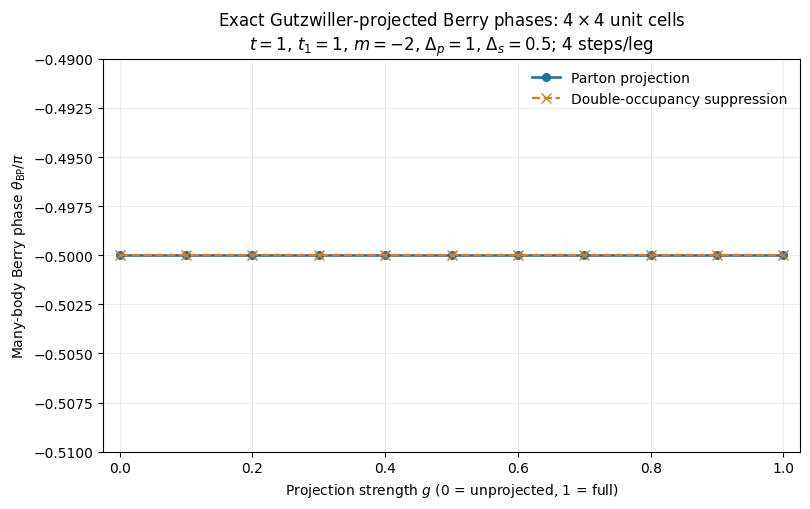

     g        parton/pi        double/pi     min |link|
  0.00  -0.500000000000  -0.500000000000   8.512749e-01
  0.10  -0.500000000000  -0.500000000000   8.550948e-01
  0.20  -0.500000000000  -0.500000000000   8.591320e-01
  0.30  -0.500000000000  -0.500000000000   8.634428e-01
  0.40  -0.500000000000  -0.500000000000   8.680929e-01
  0.50  -0.500000000000  -0.500000000000   8.731474e-01
  0.60  -0.500000000000  -0.500000000000   8.781112e-01
  0.70  -0.500000000000  -0.500000000000   8.783748e-01
  0.80  -0.500000000000  -0.500000000000   8.754857e-01
  0.90  -0.500000000000  -0.500000000000   8.702386e-01
  1.00  -0.500000000000  -0.500000000000   8.672530e-01
Figure: /Users/xuzheying/Library/CloudStorage/OneDrive-HKUST/Work Documents/AI Projects/Many body Berry phase/gutzwiller_projection_figure/projection_strength_results/numpy_projection_berry_4f454e6a5449.png


In [9]:
parton_phase = np.array([item['berry_phase_over_pi'] for item in parton_results])
double_phase = np.array([item['berry_phase_over_pi'] for item in double_results])

fig, ax = plt.subplots(figsize=(8.2, 5.2))
ax.plot(g_values, parton_phase, 'o-', color='#1676a3', lw=1.9, ms=5.5,
        label='Parton projection')
ax.plot(g_values, double_phase, 'x--', color='#dc7d21', lw=1.6, ms=6.5,
        label='Double-occupancy suppression')
ax.set_xlabel('Projection strength $g$ (0 = unprojected, 1 = full)')
ax.set_ylabel(r'Many-body Berry phase $\theta_{\mathrm{BP}}/\pi$')
ax.set_xlim(-0.025, 1.025)
ax.set_xticks(np.linspace(0, 1, 6))
ax.grid(alpha=0.22)
ax.legend(frameon=False, loc='best')
all_phases = np.concatenate((parton_phase, double_phase))
center, span = float(np.mean(all_phases)), float(np.ptp(all_phases))
margin = max(0.01, 0.12*span)
ax.set_ylim(min(float(np.min(all_phases))-margin, center-0.005),
            max(float(np.max(all_phases))+margin, center+0.005))
ax.set_title('Exact Gutzwiller-projected Berry phases: $4\\times4$ unit cells\n'
             f'$t={t:g}$, $t_1={t1:g}$, $m={m:g}$, $\\Delta_p={delta_p:g}$, '
             f'$\\Delta_s={delta_s:g}$; {steps_per_leg} steps/leg', fontsize=12)
fig.tight_layout()
fig.savefig(FIGURE_PATH, dpi=220, bbox_inches='tight')
plt.show()

print(f"{'g':>6} {'parton/pi':>16} {'double/pi':>16} {'min |link|':>14}")
for p, d in zip(parton_results, double_results):
    print(f"{p['g']:6.2f} {p['berry_phase_over_pi']:+16.12f} "
          f"{d['berry_phase_over_pi']:+16.12f} "
          f"{min(p['minimum_link_magnitude'], d['minimum_link_magnitude']):14.6e}")
print(f'Figure: {FIGURE_PATH}')